# 🧠 RAG Asistanı Adım Adım: Veri, Parçalama, Geri Getirme ve Değerlendirme

Bu notebook, [Streamlit uygulamasının](../app.py) arkasındaki RAG hattını adım adım inceler. Uygulamayla **aynı kodu** (`rag.py`) kullanır; burada ayrıca bir mantık yazılmaz.

| # | Bölüm | Soru |
|---|---|---|
| 1 | Veriyi tanıma | Bilgi havuzunda ne var, cevaplar ne kadar uzun? |
| 2 | Parçalama | Uzun cevaplar nasıl bölünüyor, neden her parçaya soru ekleniyor? |
| 3 | Geri getirme | Bir soru sorulduğunda hangi parçalar, hangi skorla geliyor? |
| 4 | Değerlendirme | Doğru SSS kaydı ne sıklıkla ilk sıralarda? |
| 5 | "Bilgi yok" eşiği | Eşik değiştikçe reddetme davranışı nasıl değişiyor? |
| 6 | Gemini modu | API anahtarı varsa aynı ölçümler çok dilli embedding ile |

Notebook **API anahtarı olmadan** baştan sona çalışır (yerel TF-IDF modu). `GOOGLE_API_KEY` ortam değişkeni tanımlıysa 6. bölüm de çalışır.

In [1]:
# Colab'da açıldıysa repoyu indir ve bağımlılıkları kur
import os, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("rag.py").exists():
    !git clone -q https://github.com/Memreu/Mental-Health-FAQ.git
    %cd Mental-Health-FAQ
    !pip install -q -r requirements.txt

ROOT = Path.cwd() if Path("rag.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
print("Proje klasörü:", ROOT.name)

Proje klasörü: Mental-Health-FAQ


In [2]:
import importlib.util
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import rag

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.3})
BLUE, RED, ORANGE, GREEN, GREY = "#2E5EAA", "#C0392B", "#E67E22", "#29A36A", "#8C8C8C"

# Değerlendirme betiğini modül olarak yükle (evaluation/evaluate.py)
spec = importlib.util.spec_from_file_location("evaluate", ROOT / "evaluation" / "evaluate.py")
ev = importlib.util.module_from_spec(spec); spec.loader.exec_module(ev)

## 1. Veriyi tanıma

Bilgi havuzu, Kaggle'daki *Mental Health FAQ for Chatbot* veri seti: her satır bir soru ve ona verilmiş açıklayıcı bir cevap.

In [3]:
df = rag.load_faq()
df["cevap_uzunlugu"] = df["Answers"].str.len()
print(f"{len(df)} soru-cevap · cevap uzunluğu: medyan {df.cevap_uzunlugu.median():.0f}, "
      f"en kısa {df.cevap_uzunlugu.min()}, en uzun {df.cevap_uzunlugu.max():,} karakter")
df[["Question_ID", "Questions", "cevap_uzunlugu"]].head()

98 soru-cevap · cevap uzunluğu: medyan 1274, en kısa 93, en uzun 8,492 karakter


,Question_ID,Questions,cevap_uzunlugu
0,1590140,What does it mean to have a mental illness?,1361
1,2110618,Who does mental illness affect?,1261
2,6361820,What causes mental illness?,1259
3,9434130,What are some of the warning signs of mental illness?,1357
4,7657263,Can people with mental illness recover?,587


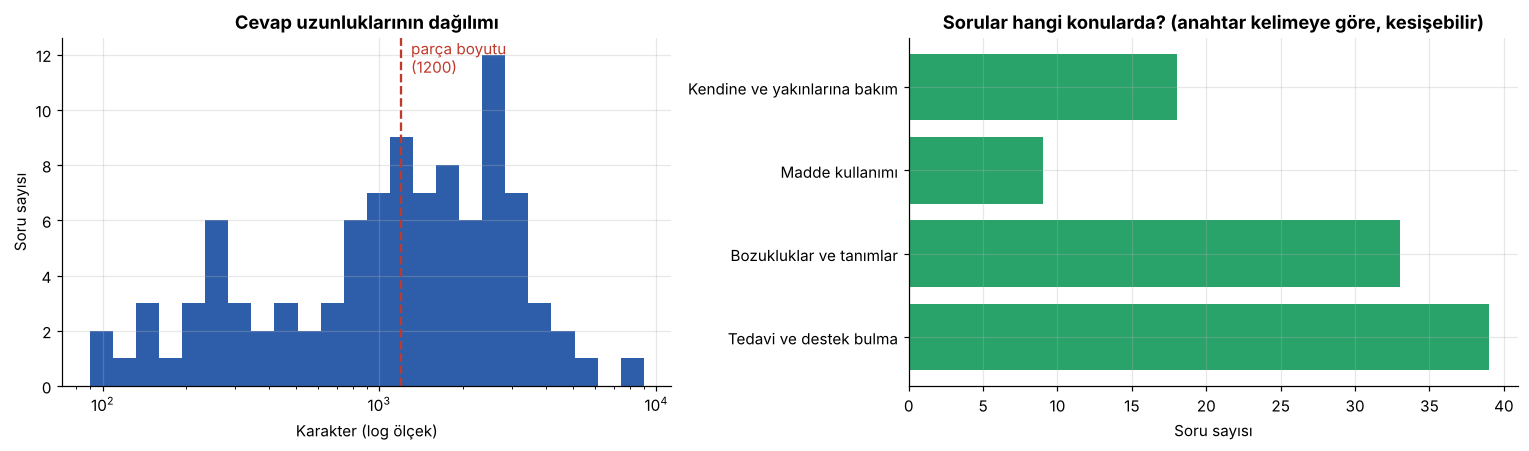

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].hist(df.cevap_uzunlugu, bins=np.logspace(np.log10(90), np.log10(9000), 25), color=BLUE)
ax[0].set_xscale("log"); ax[0].axvline(1200, color=RED, ls="--")
ax[0].text(1300, ax[0].get_ylim()[1] * 0.9, "parça boyutu\n(1200)", color=RED)
ax[0].set(title="Cevap uzunluklarının dağılımı", xlabel="Karakter (log ölçek)", ylabel="Soru sayısı")

konular = {"Tedavi ve destek bulma": r"find|help|treatment|therap|counsel|support|pay|psychiatrist|psychologist|referral",
           "Bozukluklar ve tanımlar": r"what is|difference|disorder|depress|anxiety|schizo|psychos|symptom",
           "Madde kullanımı": r"cannabis|alcohol|drug|substance|vaping|cbd|drinking",
           "Kendine ve yakınlarına bakım": r"cope|grief|lonely|friend|someone|child|parent|physical|thinking"}
sayilar = {k: df.Questions.str.lower().str.contains(v).sum() for k, v in konular.items()}
ax[1].barh(list(sayilar), list(sayilar.values()), color=GREEN)
ax[1].set(title="Sorular hangi konularda? (anahtar kelimeye göre, kesişebilir)", xlabel="Soru sayısı")
plt.tight_layout(); plt.show()

**Gözlem:** Cevapların yarısından fazlası (%53) 1.200 karakterden uzun; en uzunu 8.500 karakteri geçiyor. Bu kadar uzun bir metni tek bir vektörle temsil etmek, içindeki farklı alt konuların birbirini bastırmasına yol açar. Bu yüzden cevaplar parçalara bölünüyor.

## 2. Parçalama

`RecursiveCharacterTextSplitter` cevapları önce paragraf, sonra cümle sınırlarından bölmeye çalışır (1.200 karakter, 150 karakter örtüşme). Her parçanın başına **ait olduğu soru** eklenir: böylece uzun bir cevabın ortasındaki bir parça bile doğru soruyla eşleşebilir.

In [5]:
docs = rag.build_documents(df)
parca_sayisi = pd.Series([d.metadata["question_id"] for d in docs]).value_counts()
print(f"{len(df)} cevap → {len(docs)} parça · "
      f"{(parca_sayisi > 1).sum()} cevap birden fazla parçaya bölündü (en fazla {parca_sayisi.max()})")

en_uzun = df.loc[df.cevap_uzunlugu.idxmax()]
ornek = [d for d in docs if d.metadata["question_id"] == en_uzun.Question_ID]
print(f"\nEn uzun cevap: \"{en_uzun.Questions[:70]}...\" → {len(ornek)} parça\n")
for d in ornek[:3]:
    print(f"--- parça {d.metadata['chunk']} ({len(d.metadata['answer_chunk'])} karakter)")
    print(d.page_content[:230].replace("\n", " ") + " ...\n")

98 cevap → 196 parça · 52 cevap birden fazla parçaya bölündü (en fazla 10)

En uzun cevap: "Someone I love has been diagnosed with schizophrenia. How can I help?..." → 10 parça

--- parça 0 (649 karakter)
Question: Someone I love has been diagnosed with schizophrenia. How can I help? Answer: We naturally want to help a loved one who isn’t feeling well. How we can or should help may seem fairly obvious when a loved one experiences a ...

--- parça 1 (994 karakter)
Question: Someone I love has been diagnosed with schizophrenia. How can I help? Answer: Sometimes talking about problems or concerns can really help. It’s important to understand that talking about something difficult like experie ...

--- parça 2 (1196 karakter)
Question: Someone I love has been diagnosed with schizophrenia. How can I help? Answer: Symptoms of schizophrenia like hallucinations (sensations that aren’t real, like hearing voices) or delusions (beliefs that can’t be true, lik ...



## 3. Geri getirme

Yerel modda arama TF-IDF ile yapılır: kelime ve kelime ikilileri (bigram) ağırlıklandırılır, soru ile her parça arasındaki kosinüs benzerliği hesaplanır. Aşağıda, bilgi havuzundaki sorulardan **farklı kelimelerle** yazılmış üç soru için gelen ilk sonuçlar var.

In [6]:
retriever = rag.TfidfRetriever(docs)

def goster(soru, k=4):
    rows = [{"sıra": i, "skor": round(s, 3), "eşleşen SSS sorusu": d.metadata["question"]}
            for i, (d, s) in enumerate(retriever.search(soru, k), 1)]
    print(f"Soru: {soru}")
    display(pd.DataFrame(rows).set_index("sıra"))

for soru in ["How can I cope with losing someone I love?",
             "Is vaping bad for my health?",
             "What is the capital of France?"]:
    goster(soru)

Soru: How can I cope with losing someone I love?


,skor,eşleşen SSS sorusu
sıra,,
1,0.205,How can I manage grief?
2,0.051,Someone I love has been diagnosed with schizophrenia. How can I help?
3,0.050,Someone I love has been diagnosed with schizophrenia. How can I help?
4,0.049,Someone I love has been diagnosed with schizophrenia. How can I help?


Soru: Is vaping bad for my health?


,skor,eşleşen SSS sorusu
sıra,,
1,0.164,What is the evidence on vaping?
2,0.161,What is the evidence on vaping?
3,0.160,What is the evidence on vaping?
4,0.076,How can I challenge thinking traps?


Soru: What is the capital of France?


,skor,eşleşen SSS sorusu
sıra,,
1,0.0,What is the evidence on vaping?
2,0.0,What is the evidence on vaping?
3,0.0,What is the evidence on vaping?
4,0.0,What is the legal status (and evidence) of CBD oil?


**Gözlem:** İlk iki soruda doğru kayıt açık ara birinci geliyor. Konu dışı soruda ise en yüksek skor çok düşük; uygulama bu durumda kaynak göstermek yerine "bilgi yok" diyor (bkz. 5. bölüm).

## 4. Değerlendirme

Değerlendirme seti ([`evaluation/eval_set.csv`](../evaluation/eval_set.csv)) elle yazılmış 33 kapsam içi soru (25 İngilizce, 8 Türkçe) ve 6 kapsam dışı sorudan oluşur. Her kapsam içi soru için doğru kabul edilen SSS kaydı (veya kayıtları) belirtilmiştir.

- **hit@k:** Doğru kayıt, tekrarlar birleştirildikten sonra ilk *k* sonuçta mı?
- **MRR:** Doğru kaydın sırasının tersinin ortalaması (1. sıra = 1, 2. sıra = 0,5, ...).

In [7]:
sonuc = ev.evaluate("yerel")
ic = sonuc[sonuc.in_scope].copy()

def metrikler(g):
    return pd.Series({"soru": len(g), "hit@1": (g["rank"] == 1).mean(), "hit@3": (g["rank"] <= 3).mean(),
                      "MRR": g["rank"].map(lambda r: 1 / r if pd.notna(r) else 0).mean()})

tablo = ic.groupby("lang").apply(metrikler).rename(index={"en": "İngilizce", "tr": "Türkçe"})
tablo.loc["Tümü"] = metrikler(ic)
tablo.round(2)

,soru,hit@1,hit@3,MRR
lang,,,,
İngilizce,25.0,0.80,0.88,0.84
Türkçe,8.0,0.12,0.12,0.12
Tümü,33.0,0.64,0.70,0.67


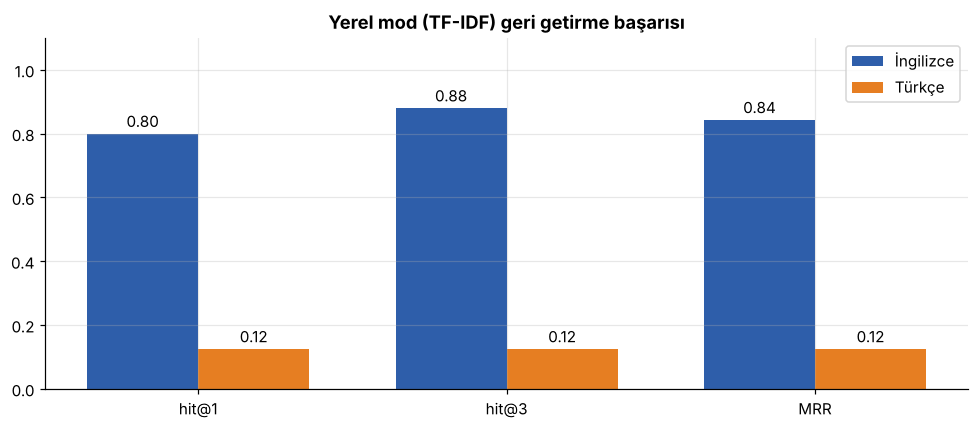

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(3); w = 0.36
for i, (dil, renk) in enumerate([("İngilizce", BLUE), ("Türkçe", ORANGE)]):
    v = tablo.loc[dil, ["hit@1", "hit@3", "MRR"]].astype(float).values
    bars = ax.bar(x + (i - 0.5) * w, v, w, color=renk, label=dil)
    ax.bar_label(bars, fmt="%.2f", padding=2)
ax.set_xticks(x, ["hit@1", "hit@3", "MRR"]); ax.set_ylim(0, 1.1)
ax.set_title("Yerel mod (TF-IDF) geri getirme başarısı"); ax.legend()
plt.tight_layout(); plt.show()

In [9]:
# İlk 3'te bulunamayan İngilizce sorular: neden kaçtılar?
kacan = ic[(ic.lang == "en") & ~(ic["rank"] <= 3)]
for q in kacan["query"]:
    ilk = retriever.search(q, 1)[0][0].metadata["question"]
    print(f"• {q}\n    → ilk sonuç: {ilk}")

• How can I tell if someone is developing a mental illness?
    → ilk sonuç: Who does mental illness affect?
• Is it possible to get better after a mental illness?
    → ilk sonuç: What's the difference between mental health and mental illness?
• What is chronic low-grade depression?
    → ilk sonuç: I’m having a hard time coping with a physical health problem. Where can I find help?


**Gözlem:**

- İngilizce sorularda doğru kayıt 5 sorunun 4'ünde **ilk sırada**. Kaçırılan sorular, SSS'tekiyle ortak kelimesi az olan ifadeler: *"get better"* ↔ *"recover"*, *"chronic low-grade depression"* ↔ *"dysthymia"*. Kelime tabanlı aramanın eş anlamlıları tanımamasının tipik sonucu bu.
- Türkçe sorularda başarı neredeyse sıfır: Türkçe kelimeler İngilizce metinde hiç geçmiyor. Bu, uygulamanın Gemini modunda **çok dilli embedding** kullanmasının nedeni.

## 5. "Bilgi yok" eşiği

Yerel modda en yüksek benzerlik skoru `LOCAL_MIN_SCORE` değerinin altındaysa uygulama cevap vermek yerine "bilgi yok" der. Eşik yükseldikçe konu dışı soruları reddetme oranı artar ama kapsam içi soruları da yanlışlıkla reddetme riski büyür.

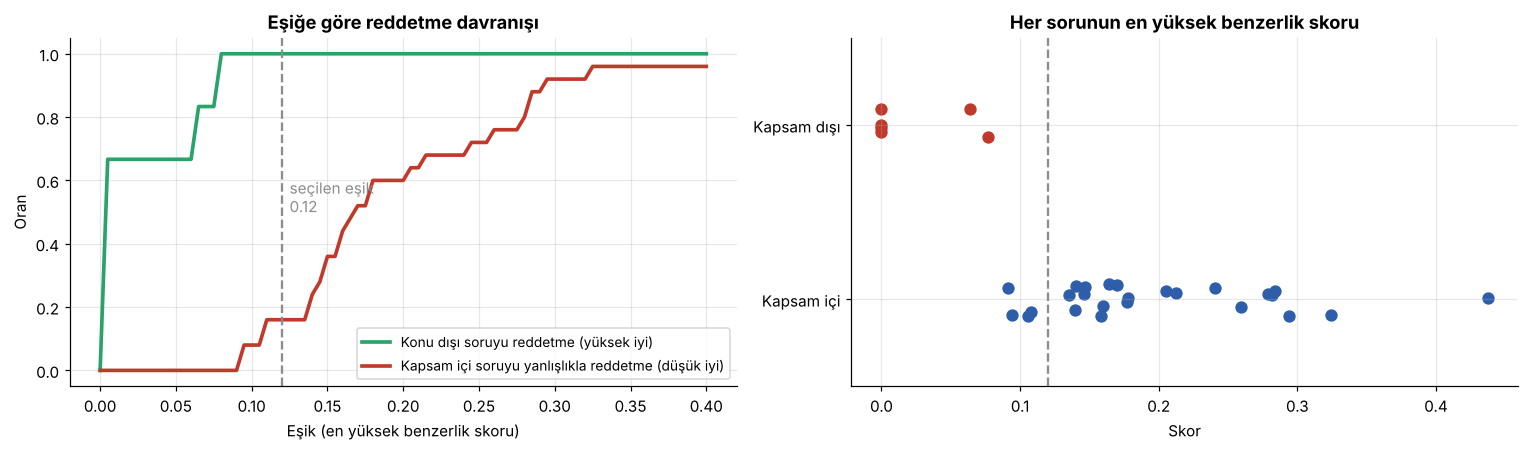

Seçilen eşik (0.12) → konu dışı soruları reddetme oranı: 100% · kapsam içi İngilizce soruları yanlışlıkla reddetme oranı: 16%


In [10]:
en_ic = sonuc[sonuc.in_scope & (sonuc.lang == "en")]
dis = sonuc[~sonuc.in_scope]
esikler = np.linspace(0, 0.4, 81)
dogru_red = [(dis.top_score < t).mean() for t in esikler]
yanlis_red = [(en_ic.top_score < t).mean() for t in esikler]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(esikler, dogru_red, color=GREEN, lw=2.4, label="Konu dışı soruyu reddetme (yüksek iyi)")
ax[0].plot(esikler, yanlis_red, color=RED, lw=2.4, label="Kapsam içi soruyu yanlışlıkla reddetme (düşük iyi)")
ax[0].axvline(rag.LOCAL_MIN_SCORE, color=GREY, ls="--")
ax[0].text(rag.LOCAL_MIN_SCORE + 0.005, 0.5, f"seçilen eşik\n{rag.LOCAL_MIN_SCORE}", color=GREY)
ax[0].set(title="Eşiğe göre reddetme davranışı", xlabel="Eşik (en yüksek benzerlik skoru)", ylabel="Oran")
ax[0].legend(loc="lower right", fontsize=9)

ax[1].scatter(en_ic.top_score, np.zeros(len(en_ic)) + np.random.default_rng(0).uniform(-.1, .1, len(en_ic)),
              color=BLUE, s=50, label="Kapsam içi (İngilizce)")
ax[1].scatter(dis.top_score, np.ones(len(dis)) + np.random.default_rng(1).uniform(-.1, .1, len(dis)),
              color=RED, s=50, label="Kapsam dışı")
ax[1].axvline(rag.LOCAL_MIN_SCORE, color=GREY, ls="--")
ax[1].set_yticks([0, 1], ["Kapsam içi", "Kapsam dışı"]); ax[1].set_ylim(-0.5, 1.5)
ax[1].set(title="Her sorunun en yüksek benzerlik skoru", xlabel="Skor")
plt.tight_layout(); plt.show()

print(f"Seçilen eşik ({rag.LOCAL_MIN_SCORE}) → konu dışı soruları reddetme oranı: {(dis.top_score < rag.LOCAL_MIN_SCORE).mean():.0%} · "
      f"kapsam içi İngilizce soruları yanlışlıkla reddetme oranı: {(en_ic.top_score < rag.LOCAL_MIN_SCORE).mean():.0%}")

**Gözlem:** Konu dışı soruların skorları 0,08'in altında, kapsam içi soruların büyük çoğunluğu ise belirgin şekilde yukarıda. 0,12 eşiği tüm konu dışı soruları eliyor ama kapsam içi İngilizce soruların %16'sını da reddediyor.

Bu küçük sette **0,08–0,09** arası bir eşik iki hatayı da sıfırlıyor gibi görünüyor. Yine de eşiği yalnızca 6 kapsam dışı soruya bakarak düşürmek aşırı uyum (overfitting) riski taşır. Değerlendirme seti büyüdükçe bu grafik yeniden çizilip eşik güncellenmeli.

> ⚠️ Yanlışlıkla reddetme, hassas bir alanda alakasız bir cevabı güvenle sunmaktan **daha az zararlı** bir hata türü. Bu yüzden eşik şimdilik bilinçli olarak temkinli tarafta tutuldu.

## 6. Gemini modu (isteğe bağlı)

`GOOGLE_API_KEY` tanımlıysa aynı değerlendirme `gemini-embedding-001` ile tekrarlanır ve örnek bir Türkçe soru Gemini'ye sorulur. Anahtar yoksa bu bölüm atlanır.

```bash
export GOOGLE_API_KEY="..."   # Colab'da: os.environ["GOOGLE_API_KEY"] = "..."
```

In [11]:
if os.environ.get("GOOGLE_API_KEY"):
    sonuc_g = ev.evaluate("gemini")
    ic_g = sonuc_g[sonuc_g.in_scope]
    karsilastirma = pd.DataFrame({
        "Yerel (TF-IDF)": ic.groupby("lang").apply(metrikler)["hit@3"],
        "Gemini embedding": ic_g.groupby("lang").apply(metrikler)["hit@3"],
    }).rename(index={"en": "İngilizce", "tr": "Türkçe"})
    display(karsilastirma.round(2))

    pipeline = rag.build_pipeline(os.environ["GOOGLE_API_KEY"])
    cevap = pipeline.ask("Stres ile kaygı arasındaki fark nedir?")
    print(cevap.text)
    print("\nKaynaklar:", [s.question for s in cevap.sources])
else:
    print("GOOGLE_API_KEY tanımlı değil: Gemini bölümü atlandı (notebook'un geri kalanı yerel modda çalıştı).")

GOOGLE_API_KEY tanımlı değil: Gemini bölümü atlandı (notebook'un geri kalanı yerel modda çalıştı).


## Sonuç

| Bulgu | Sonuç |
|---|---|
| Parçalama gerekli | Cevapların %53'ü 1.200 karakterden uzun; 98 cevap 196 parçaya bölünüyor |
| Yerel mod İngilizcede güçlü | hit@1 0,80 · hit@3 0,88 · MRR 0,84 |
| Yerel mod Türkçede yetersiz | hit@3 0,12: çok dilli embedding (Gemini modu) şart |
| Temkinli eşik | Konu dışı soruların tamamı reddediliyor, kapsam içi soruların %16'sı da yanlışlıkla reddediliyor |

**Sonraki adımlar:** Gemini modunun sonuçlarını bu notebook'a eklemek, değerlendirme setini büyütmek ve yanıt kalitesini (ör. RAGAS *faithfulness*) ölçmek.